**Purpose:** Imports OpenCV, NumPy, and Matplotlib for edge detection.

In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

**Purpose:** Defines Sobel edge detection using horizontal and vertical gradient kernels.

In [6]:
def sobel_edge_detection(img):

    sobel_x = np.array([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1]
    ])

    sobel_y = np.array([
        [-1, -2, -1],
        [ 0,  0,  0],
        [ 1,  2,  1]
    ])

    rows, cols = img.shape
    result = np.zeros((rows, cols), dtype=np.uint8)

    for i in range(1, rows - 1):
        for j in range(1, cols - 1):

            region = img[i-1:i+2, j-1:j+2].astype(np.int16)

            gx = np.sum(region * sobel_x)
            gy = np.sum(region * sobel_y)

            magnitude = np.sqrt(gx**2 + gy**2)

            result[i, j] = min(255, int(magnitude))

    return result

**Purpose:** Defines Prewitt edge detection using horizontal and vertical gradient kernels.

In [7]:
def prewitt_edge_detection(img):

    prewitt_x = np.array([
        [-1, 0, 1],
        [-1, 0, 1],
        [-1, 0, 1]
    ])

    prewitt_y = np.array([
        [-1, -1, -1],
        [ 0,  0,  0],
        [ 1,  1,  1]
    ])

    rows, cols = img.shape
    result = np.zeros((rows, cols), dtype=np.uint8)

    for i in range(1, rows - 1):
        for j in range(1, cols - 1):

            region = img[i-1:i+2, j-1:j+2].astype(np.int16)

            gx = np.sum(region * prewitt_x)
            gy = np.sum(region * prewitt_y)

            magnitude = np.sqrt(gx**2 + gy**2)

            result[i, j] = min(255, int(magnitude))

    return result

**Purpose:** Runs Sobel, Prewitt, and Canny edge detection and displays the results.

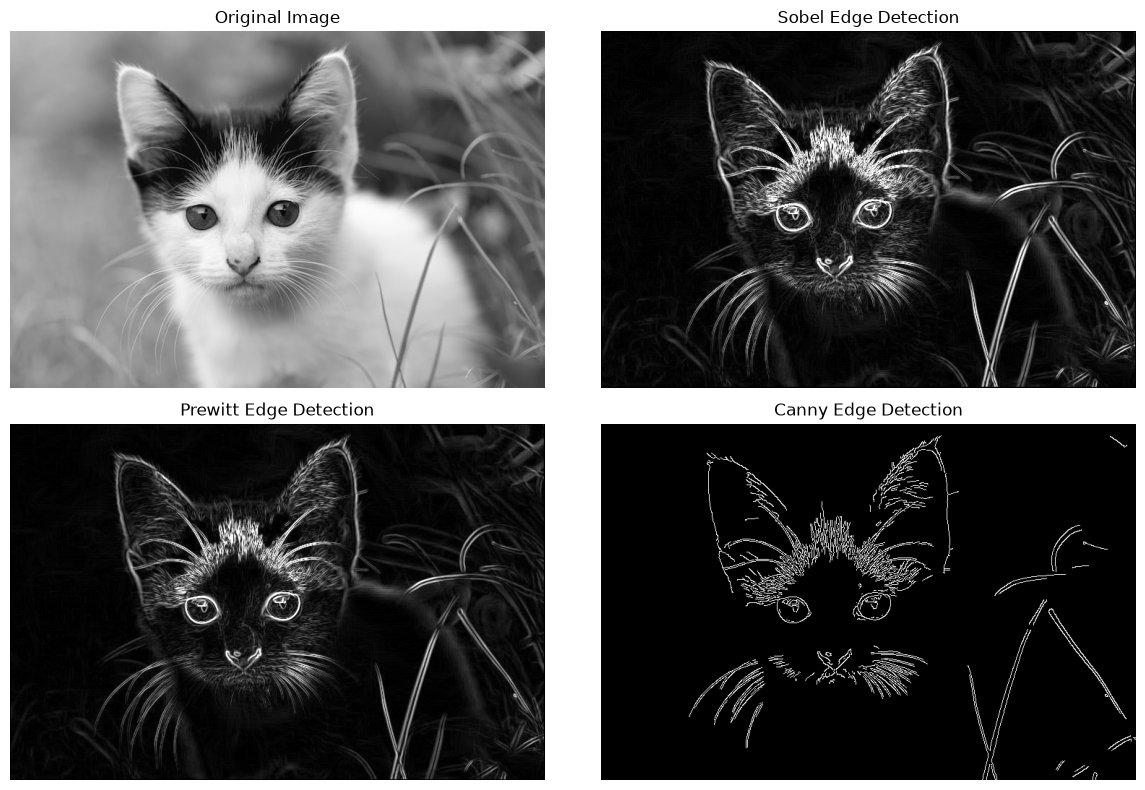

In [8]:
img = cv2.imread("../cat.jpg", 0)

if img is None:
    print("Image not found!")
    exit()


# Apply Edge Detection
sobel = sobel_edge_detection(img)
prewitt = prewitt_edge_detection(img)

# Canny Edge Detection (OpenCV)
canny = cv2.Canny(img, 100, 200)


# Display Results
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(sobel, cmap='gray')
plt.title("Sobel Edge Detection")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(prewitt, cmap='gray')
plt.title("Prewitt Edge Detection")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(canny, cmap='gray')
plt.title("Canny Edge Detection")
plt.axis("off")

plt.tight_layout()
plt.show()

**Purpose:** This cell is intentionally left blank.